# Salifort Motors | Understanding employee departures
**Sebastián Madrigal López · Google Advanced Data Analytics capstone project**

This project examines employee departures in the Salifort Motors case study to identify
priorities for retention research. It combines exploratory analysis with decision-tree
and random-forest classification.

This notebook covers **Plan** and **Analyze** in the PACE framework. See the
[project overview](../README.md) for the main findings and the
[modeling notebook](02_modeling_and_evaluation.ipynb) for **Construct** and **Execute**.


## 1. Business question and analytical scope
Which employee characteristics are associated with departure, and how accurately can
recorded departures be classified? The target is `left`: **1 = left, 0 = stayed**.

The analysis focuses on workload, tenure, satisfaction and evaluations. Findings support
questions for HR about project allocation, career development and employee experience.
Collection dates, exit type and predictor measurement timing require further documentation.


## 2. Setup
Import the analysis packages and set paths relative to the repository folder.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split


In [2]:
# A notebook can start from the repository folder or its notebooks subfolder.
project_folder = Path.cwd()
if project_folder.name == 'notebooks':
    project_folder = project_folder.parent

data_file = project_folder / 'data' / 'raw' / 'HR_capstone_dataset.csv'
reports_folder = project_folder / 'reports'
figures_folder = reports_folder / 'figures'
tables_folder = reports_folder / 'tables'

if not data_file.is_file():
    raise FileNotFoundError('Open this notebook from the repository or notebooks folder.')

figures_folder.mkdir(parents=True, exist_ok=True)
tables_folder.mkdir(parents=True, exist_ok=True)


In [3]:
# Shared colors keep the figures consistent across both notebooks.
teal = '#167D8D'
coral = '#DB765F'
ink = '#16324A'
muted = '#627487'

plt.rcParams.update({
    'figure.dpi': 110,
    'savefig.dpi': 170,
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.labelcolor': ink,
    'text.color': ink,
    'xtick.color': muted,
    'ytick.color': muted,
    'axes.titleweight': 'bold',
    'axes.titlepad': 15,
})
pd.set_option('display.max_columns', 20)


## 3. Data source and quality checks
The supplied `HR_capstone_dataset.csv` is associated with
[HR Analytics and Job Prediction](https://www.kaggle.com/datasets/mfaisalqureshi/hr-analytics-and-job-prediction).
Salifort Motors provides the educational business scenario. The
[data dictionary](../data/README.md) documents the variables and source limitations.


In [4]:
df = pd.read_csv(data_file)

print('Rows and columns:', df.shape)
display(df.head())


Rows and columns: (14999, 10)


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [5]:
df.info()

print('\nMissing values by column:')
display(df.isna().sum())

print('Exact repeated rows:', df.duplicated().sum())
print('Target values:', df['left'].unique())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   Department             14999 non-null  object 
 9   salary                 14999 non-null  object 
dtypes: float64(2), int64(6), object(2)
memory usage: 1.1+ MB

Missing values by column:
Exact repeated rows: 3008
Target values: [1 0]


satisfaction_level       0
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
Work_accident            0
left                     0
promotion_last_5years    0
Department               0
salary                   0
dtype: int64

In [6]:
expected_columns = [
    'satisfaction_level', 'last_evaluation', 'number_project',
    'average_montly_hours', 'time_spend_company', 'Work_accident',
    'left', 'promotion_last_5years', 'Department', 'salary',
]

if set(df.columns) != set(expected_columns):
    raise ValueError('Unexpected columns. Review the CSV and data/README.md.')
if df.isna().any().any():
    raise ValueError('Missing values found. Review them before continuing.')
if not df['left'].isin([0, 1]).all():
    raise ValueError('The target must contain only 0 (stayed) and 1 (left).')


## 4. Data preparation
Remove exact repeated rows and standardize column names. This assumes repeated records
are redundant; verifying employee identity would require a unique identifier.
Valid long-tenure and high-workload observations are retained.


In [7]:
# Keep the source data in df and the analysis data in df1.
df1 = df.drop_duplicates().copy()

df1 = df1.rename(columns={
    'average_montly_hours': 'average_monthly_hours',
    'time_spend_company': 'tenure',
    'Work_accident': 'work_accident',
    'Department': 'department',
})

# Preserve source row indices for split traceability.
print('Rows before cleaning:', len(df))
print('Exact repeats removed:', len(df) - len(df1))
print('Rows after cleaning:', len(df1))
display(df1.head())


Rows before cleaning: 14999
Exact repeats removed: 3008
Rows after cleaning: 11991


,satisfaction_level,last_evaluation,number_project,average_monthly_hours,tenure,work_accident,left,promotion_last_5years,department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


In [8]:
population_summary = pd.DataFrame({
    'population': ['Raw file', 'After removing exact repeats'],
    'rows': [len(df), len(df1)],
    'departures': [df['left'].sum(), df1['left'].sum()],
    'departure_rate': [df['left'].mean(), df1['left'].mean()],
})
display(population_summary.round(4))


,population,rows,departures,departure_rate
0,Raw file,14999,3571,0.2381
1,After removing exact repeats,11991,1991,0.1660


The source contains **14,999 rows and 10 columns**, with complete values. Removing
**3,008 exact repeats** leaves **11,991 records**. The departure rate is **23.8%** in the
source data and **16.6%** in the analysis population.


## 5. Training and test partitions
A stratified **75/25 split** with `random_state=0` preserves the class proportions.
Detailed exploration uses training rows. The test partition supports the final
comparison after model selection. Evaluation is internal to the supplied dataset.


In [9]:
train_data, test_data = train_test_split(
    df1,
    test_size=0.25,
    stratify=df1['left'],
    random_state=0,
)

split_summary = pd.DataFrame({
    'partition': ['Train', 'Test'],
    'rows': [len(train_data), len(test_data)],
    'departures': [train_data['left'].sum(), test_data['left'].sum()],
    'departure_rate': [train_data['left'].mean(), test_data['left'].mean()],
})
display(split_summary.round(4))


,partition,rows,departures,departure_rate
0,Train,8993,1493,0.1660
1,Test,2998,498,0.1661


In [10]:
display(train_data.describe().round(2))
display(train_data['salary'].value_counts())


,satisfaction_level,last_evaluation,number_project,average_monthly_hours,tenure,work_accident,left,promotion_last_5years
count,8993.00,8993.00,8993.00,8993.00,8993.00,8993.00,8993.00,8993.00
mean,0.63,0.72,3.80,200.84,3.36,0.15,0.17,0.02
std,0.24,0.17,1.16,48.81,1.33,0.36,0.37,0.13
min,0.09,0.36,2.00,96.00,2.00,0.00,0.00,0.00
25%,0.48,0.57,3.00,158.00,3.00,0.00,0.00,0.00
50%,0.66,0.72,4.00,201.00,3.00,0.00,0.00,0.00
75%,0.82,0.86,5.00,243.00,4.00,0.00,0.00,0.00
max,1.00,1.00,7.00,310.00,10.00,1.00,1.00,1.00


salary
low       4351
medium    3895
high       747
Name: count, dtype: int64

## 6. Workload and departures
Compare departure rates and sample sizes across project-count groups. For the binary
target, the group mean is the departure rate and the sum is the number of departures.


In [11]:
project_rates = train_data.groupby('number_project')['left'].agg(
    employees='size',
    departures='sum',
    departure_rate='mean',
)
display(project_rates.round(4))


,employees,departures,departure_rate
number_project,,,
2,1192,649,0.5445
3,2649,31,0.0117
4,2758,173,0.0627
5,1686,259,0.1536
6,600,273,0.4550
7,108,108,1.0000


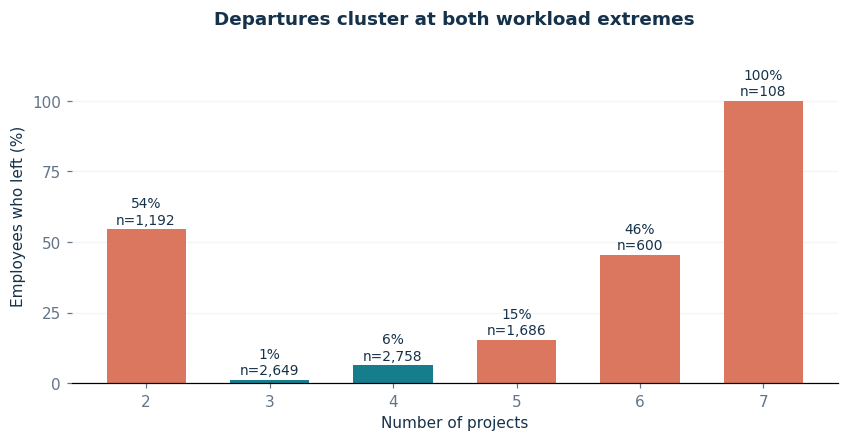

In [12]:
project_colors = []
for project_count in project_rates.index:
    if project_count == 2 or project_count >= 5:
        project_colors.append(coral)
    else:
        project_colors.append(teal)

fig, ax = plt.subplots(figsize=(7.6, 3.9), layout='constrained')
bars = ax.bar(
    project_rates.index.astype(str),
    project_rates['departure_rate'] * 100,
    color=project_colors,
    width=0.64,
)

# Label each bar with its departure rate and the number of records in that group.
for position, bar in enumerate(bars):
    row = project_rates.iloc[position]
    label = f'{row["departure_rate"]:.0%}\nn={int(row["employees"]):,}'
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2,
            label, ha='center', fontsize=9)

ax.set_title('Departures cluster at both workload extremes')
ax.set_xlabel('Number of projects')
ax.set_ylabel('Employees who left (%)')
ax.set_ylim(0, 119)
ax.set_yticks([0, 25, 50, 75, 100])
ax.spines['left'].set_visible(False)
ax.grid(axis='y', alpha=0.13)
ax.set_axisbelow(True)

fig.savefig(figures_folder / 'departures_by_projects.png', bbox_inches='tight')
plt.show()


Departure rates are elevated at both workload extremes. The seven-project group has
108 training records, so its sample size deserves attention when interpreting the rate.

Monthly hours and satisfaction provide further context for these patterns.


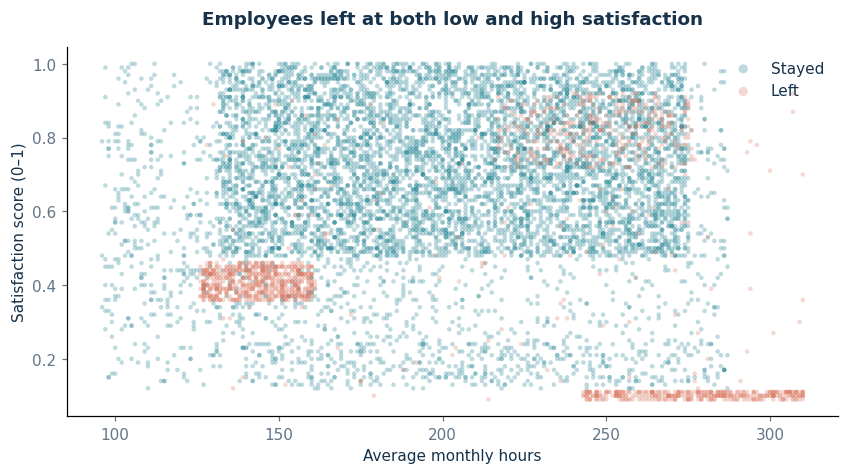

In [13]:
stayed = train_data.loc[train_data['left'] == 0]
left = train_data.loc[train_data['left'] == 1]

fig, ax = plt.subplots(figsize=(7.6, 4.2), layout='constrained')
ax.scatter(stayed['average_monthly_hours'], stayed['satisfaction_level'],
           s=9, alpha=0.28, color=teal, label='Stayed', edgecolors='none')
ax.scatter(left['average_monthly_hours'], left['satisfaction_level'],
           s=9, alpha=0.28, color=coral, label='Left', edgecolors='none')

ax.set_title('Employees left at both low and high satisfaction')
ax.set_xlabel('Average monthly hours')
ax.set_ylabel('Satisfaction score (0–1)')
ax.legend(frameon=False, markerscale=2)

fig.savefig(figures_folder / 'workload_and_satisfaction.png', bbox_inches='tight')
plt.show()


Departures appear in several clusters spanning workload and satisfaction levels.
These structured patterns warrant checking the dataset's collection process before
generalizing to another workforce.

A fixed **175-hour cutoff** defines the workload indicator used in the reduced-input
modeling scenario.


In [14]:
workload_data = train_data.copy()
workload_data['workload'] = np.where(
    workload_data['average_monthly_hours'] > 175,
    '>175 hours/month',
    '<=175 hours/month',
)

workload_rates = workload_data.groupby('workload')['left'].agg(
    employees='size', departures='sum', departure_rate='mean'
)
display(workload_rates.round(4))


,employees,departures,departure_rate
workload,,,
<=175 hours/month,3231,672,0.2080
>175 hours/month,5762,821,0.1425


## 7. Tenure, department and salary


In [15]:
tenure_rates = train_data.groupby('tenure')['left'].agg(
    employees='size', departures='sum', departure_rate='mean'
)
display(tenure_rates.round(4))


,employees,departures,departure_rate
tenure,,,
2,2195,24,0.0109
3,3903,659,0.1688
4,1491,375,0.2515
5,772,351,0.4547
6,418,84,0.2010
7,74,0,0.0000
8,61,0,0.0000
10,79,0,0.0000


In [16]:
department_rates = train_data.groupby('department')['left'].agg(
    employees='size', departures='sum', departure_rate='mean'
)
display(department_rates.sort_values('departure_rate', ascending=False).round(4))


,employees,departures,departure_rate
department,,,
accounting,464,85,0.1832
technical,1687,293,0.1737
hr,470,81,0.1723
marketing,492,84,0.1707
sales,2417,408,0.1688
support,1392,234,0.1681
IT,741,124,0.1673
product_mng,493,80,0.1623
RandD,519,66,0.1272


In [17]:
salary_rates = train_data.groupby('salary')['left'].agg(
    employees='size', departures='sum', departure_rate='mean'
)
salary_rates = salary_rates.reindex(['low', 'medium', 'high'])
display(salary_rates.round(4))


,employees,departures,departure_rate
salary,,,
low,4351,886,0.2036
medium,3895,571,0.1466
high,747,36,0.0482


These group rates describe unadjusted associations. Salary is measured in three ordered
categories: low, medium and high. Differences between groups provide priorities for
further investigation.

## 8. Modeling plan
- Compare a majority-class baseline, a decision tree and a random forest.
- Evaluate full inputs and a reduced scenario that removes satisfaction and replaces
  monthly hours with the workload indicator.
- Fit categorical encoders within each cross-validation training fold.
- Select hyperparameters and the reduced-input model by mean CV ROC AUC.
- Report average precision, precision, recall, F1 and accuracy for `left=1`.
- Use the default 0.5 decision threshold for the final comparison.

Continue with [Modeling and evaluation](02_modeling_and_evaluation.ipynb).


## Appendix: exported outputs
Save descriptive tables and a data audit, including the source-file fingerprint.


In [18]:
import hashlib
import json


In [19]:
# This fingerprint identifies the exact source file used in the analysis.
source_hash = hashlib.sha256(data_file.read_bytes()).hexdigest()

audit = {
    'raw_rows': len(df),
    'columns': df.shape[1],
    'duplicate_rows_removed': len(df) - len(df1),
    'analysis_rows': len(df1),
    'missing_values': int(df.isna().sum().sum()),
    'raw_departures': int(df['left'].sum()),
    'analysis_departures': int(df1['left'].sum()),
    'analysis_departure_rate': float(df1['left'].mean()),
    'source_sha256': source_hash,
}


In [20]:
project_rates.to_csv(tables_folder / 'departures_by_projects_train.csv')
tenure_rates.to_csv(tables_folder / 'departures_by_tenure_train.csv')
department_rates.to_csv(tables_folder / 'departures_by_department_train.csv')
split_summary.to_csv(tables_folder / 'split_summary.csv', index=False)

audit_text = json.dumps(audit, indent=2) + '\n'
(reports_folder / 'data_audit.json').write_text(audit_text)
print('Saved the audit, descriptive tables and figures.')


Saved the audit, descriptive tables and figures.
